# 10 — Narrow joint Optuna refinement
Reuse the saved winners from 08 and 09, existing sample/features cache and the exact same split. Jointly tune learning rate, weight decay, dropout, narration sampling weight, heads and feedforward width. Model width stays 256 with two Transformer layers and frozen encoders.

Run cells in order. CONFIG values and automatically derived ranges are in the first code cell. Learning rate uses 0.5–1.5 times the selected value; weight decay uses 0.5–2 times it; dropout uses ±0.1; sampling uses ±0.5. Architecture choices include both prior winners and adjacent tested values. TPE starts with both prior winning configurations, then explores their neighborhood.

**Budget:** 20 trials × 3 fixed seeds (42, 123, 2026), then a five-seed report for the winner. Completed matching runs resume; interrupted seeds restart. Results persist separately under `runs/optuna_joint/`. The first two trials reevaluate the previous winners using the shared architecture implementation.

The final cells plot history/importance and refresh `BestParamTuning` across 08, 09 and 10. Compare five-seed mean/std rather than only one checkpoint score. Continued tuning reuses development validation data; it is not an independent test evaluation. This notebook does not tune the decision threshold.


**Padded-box experiment:** retains original DETR features and adds frozen local DINOv2 crop features. Uses this folder's caches, split snapshot, studies and checkpoints.


In [1]:
# Reuse missing base caches in this isolated experiment before checking prerequisites.
from config import reuse_base_caches
reuse_base_caches()

# Cell purpose: Reuse cached samples and prior winners; define a small joint search neighborhood.
# Inputs: samples.pt, study manifests and saved best_parameters.json from notebooks 08/09.
# Outputs: Fixed split/seeds, parent study metadata and six local search ranges. No training yet.
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from config import CONFIG, fingerprint, save_json, require_cache
from training_architecture_runs import train_one_seed, summarize_runs, split_manifest, validate_split
try:
    import optuna
except ImportError as error:
    raise ImportError('Run %pip install "optuna>=4,<6" in this kernel first.') from error

CACHE = CONFIG['cache_dir']
RUN = CONFIG['run_dir']
require_cache(CACHE / 'samples.pt', '04_build_training_samples.ipynb')
# Refresh stale padded features before reusing samples/checkpoints.
from config import run_stage
run_stage('04_build_training_samples.ipynb')
data = torch.load(CACHE / 'samples.pt', map_location='cpu', weights_only=True)
validate_split(data)
SPLIT = split_manifest(data)
SEARCH_SEEDS = [42, 123, 2026]
REPORT_SEEDS = [42, 123, 2026, 7, 99]

# CONFIG: Point these folders to the completed 08 and 09 studies.
PARENT_FOLDERS = [RUN / 'optuna_tuning', RUN / 'optuna_architecture']
PARENT_STUDY_NAMES = ['fixed_split_macro_f1_v1', 'fixed_split_architecture_v1']
architecture_manifest = json.loads((PARENT_FOLDERS[1] / 'manifest.json').read_text(encoding='utf-8'))
ORIGINAL_ARCHITECTURE = {name: architecture_manifest['base_params'][name]
                         for name in ['num_heads', 'dim_feedforward']}
PARENTS, parent_params = [], []
for folder, parent_name in zip(PARENT_FOLDERS, PARENT_STUDY_NAMES):
    selected_file = folder / 'best_parameters.json'
    parent_manifest = json.loads((folder / 'manifest.json').read_text(encoding='utf-8'))
    # Read the current database winner when possible, rather than relying on a stale JSON report.
    if (folder / 'study.db').exists():
        parent_study = optuna.load_study(study_name=parent_name,
            storage='sqlite:///' + (folder / 'study.db').resolve().as_posix())
        completed = [t for t in parent_study.trials if t.state == optuna.trial.TrialState.COMPLETE]
        assert completed, f'No completed trials in {folder.name}; finish its search first.'
        parent_best = parent_study.best_trial
        selected_params = dict(parent_manifest['base_params'])
        selected_params.update(parent_best.params)
        selected = {'trial': parent_best.number, 'params': selected_params,
                    'search_mean_macro_f1': parent_best.value, 'split': parent_manifest['split'],
                    'report_seeds': parent_manifest['report_seeds']}
        assert all(t.state.is_finished() for t in parent_study.trials), f'{folder.name} has unfinished trials.'
        print(folder.name, ': using database winner from', len(completed), 'completed trials')
    else:
        assert selected_file.exists(), f'No stored winner in {folder.name}; run its search first.'
        selected = json.loads(selected_file.read_text(encoding='utf-8'))
    assert selected['split'] == SPLIT == parent_manifest['split'], 'Parent split/cache differs.'
    assert parent_manifest['search_seeds'] == SEARCH_SEEDS, 'Search seeds differ.'
    assert selected['report_seeds'] == REPORT_SEEDS, 'Report seeds differ.'
    params = dict(selected['params'])
    for name, value in ORIGINAL_ARCHITECTURE.items():
        params.setdefault(name, value)
    parent_params.append(params)
    PARENTS.append({'folder': folder.name, 'trial': selected['trial'],
                    'mean_macro_f1': selected['search_mean_macro_f1'], 'params': params})
assert parent_params[0]['batch_size'] == parent_params[1]['batch_size']
assert parent_params[0]['epochs'] == parent_params[1]['epochs']

# Center the neighborhood on the better prior winner, while including both winners explicitly.
BASE_PARAMS = dict(PARENTS[max(range(len(PARENTS)), key=lambda i: PARENTS[i]['mean_macro_f1'])]['params'])
lr_values = [p['lr'] for p in parent_params]
wd_values = [p['weight_decay'] for p in parent_params]
dropout_choices = sorted({round(min(0.8, max(0.0, p['dropout'] + offset)), 6)
                          for p in parent_params for offset in [-0.1, 0.0, 0.1]})
sampling_choices = sorted({max(0.5, p['narration_sampling_weight'] + offset)
                           for p in parent_params for offset in [-0.5, 0.0, 0.5]})
# Use immediate neighbors from the original architecture grid, plus both winners.
def neighbors(value, grid):
    grid = sorted(set(grid) | {value})
    index = grid.index(value)
    return grid[max(0, index - 1):min(len(grid), index + 2)]

# Architecture candidate grids also come from the previous study's saved search space.
head_grid = architecture_manifest['search_space']['num_heads']
feedforward_grid = architecture_manifest['search_space']['dim_feedforward']
SEARCH_SPACE = {
    'lr': [min(lr_values) * 0.5, max(lr_values) * 1.5],
    'weight_decay': [max(1e-8, min(wd_values) * 0.5), max(1e-7, max(wd_values) * 2)],
    'dropout': dropout_choices, 'narration_sampling_weight': sampling_choices,
    'num_heads': sorted(set(neighbors(BASE_PARAMS['num_heads'], head_grid)) | {p['num_heads'] for p in parent_params}),
    'dim_feedforward': sorted(set(neighbors(BASE_PARAMS['dim_feedforward'], feedforward_grid)) | {p['dim_feedforward'] for p in parent_params}),
}
# CONFIG: Tighten any ranges above before the first run; changes later require a new OUTPUT folder.
TOTAL_TRIALS = 20
STUDY_NAME = 'fixed_split_joint_refinement_v1'
OUTPUT = RUN / 'optuna_joint'
assert all(256 % heads == 0 for heads in SEARCH_SPACE['num_heads'])
print('Fixed split:', len(SPLIT['train_sequences']), 'train /', len(SPLIT['val_sequences']), 'validation')
display(pd.DataFrame(PARENTS))
print('Joint search:', SEARCH_SPACE)


Running prerequisite: 04_build_training_samples.ipynb
Running prerequisite: 03a_cache_dino_crops.ipynb
Local encoder: C:\MODELS\dinov2-small
Padding per side: 0.2 | matching feature cache: True
DINO features: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\cache\dino.pt | sequences: 80
Reuse matching padded samples: True
Exact original split: 64 train / 16 validation
Original train class counts: [1142, 50]
Feature widths: text 768, DETR 256, DINO 384, geometry 4, tail 2; fused input 688.
Saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\cache\samples.pt
optuna_tuning : using database winner from 20 completed trials
optuna_architecture : using database winner from 9 completed trials
Fixed split: 64 train / 16 validation


,folder,trial,mean_macro_f1,params
0,optuna_tuning,17,0.815944,"{'lr': 0.0007773311543779756, 'weight_decay': ..."
1,optuna_architecture,6,0.821902,"{'lr': 0.0007773311543779756, 'weight_decay': ..."


Joint search: {'lr': [0.0003886655771889878, 0.0011659967315669633], 'weight_decay': [0.00028483978714483835, 0.0011393591485793534], 'dropout': [0.0, 0.1, 0.2], 'narration_sampling_weight': [1.5, 2.0, 2.5], 'num_heads': [2, 4, 8], 'dim_feedforward': [512, 1024, 2048]}


Create or resume a persistent study after checking data, code and search-setting identity.


In [2]:
# Cell purpose: Create or resume a persistent study after checking data, code and search-setting identity.
# Inputs: The frozen experiment manifest and the study SQLite file, if present.
# Outputs: A seeded TPE study with no pruning and the baseline queued first.

OUTPUT.mkdir(parents=True, exist_ok=True)
# Reject study reuse after the model or shared training loop has changed.
code_hashes = {name: hashlib.sha256(Path(name).read_bytes()).hexdigest()
               for name in ['model_architecture.py', 'training_architecture_runs.py']}
# Record the exact experiment identity and reject incompatible results on a later rerun.
manifest = {'split': SPLIT, 'base_params': BASE_PARAMS, 'search_seeds': SEARCH_SEEDS,
            'report_seeds': REPORT_SEEDS, 'search_space': SEARCH_SPACE, 'code': code_hashes,
            'objective': 'mean_macro_f1', 'selection': 'macro_f1', 'parents': PARENTS}
manifest_file = OUTPUT / 'manifest.json'
if manifest_file.exists():
    assert json.loads(manifest_file.read_text(encoding='utf-8')) == manifest, 'Study settings changed; choose a new OUTPUT folder.'
save_json(manifest_file, manifest)

# Persist study trials in a local SQLite database so completed optimization work survives notebook restarts.
storage = 'sqlite:///' + (OUTPUT / 'study.db').resolve().as_posix()
# Maximize mean macro F1 using seeded TPE; pruning is intentionally disabled.
study = optuna.create_study(study_name=STUDY_NAME, storage=storage, direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=8),
    pruner=optuna.pruners.NopPruner(), load_if_exists=True)
study_id = fingerprint(manifest)
if study.user_attrs.get('experiment_id') is not None:
    assert study.user_attrs['experiment_id'] == study_id, 'Study belongs to another dataset/settings.'
study.set_user_attr('experiment_id', study_id)
# Queue both previous winners once as reference configurations for the new study.
if not study.trials:
    for params in parent_params:
        study.enqueue_trial({key: params[key] for key in SEARCH_SPACE}, skip_if_exists=True)
print('Stored trials:', len(study.trials), '| database:', OUTPUT / 'study.db')

[I 2026-10-10 06:07:49,740] A new study created in RDB with name: fixed_split_joint_refinement_v1


Stored trials: 2 | database: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\runs\optuna_joint\study.db


Define the mean-over-seeds objective and run only the remaining trial budget.


In [3]:
# Cell purpose: Define the mean-over-seeds objective and run only the remaining trial budget.
# Inputs: Suggested hyperparameters, fixed search seeds and reusable seed-run artifacts.
# Outputs: Persistent trial results, trials.csv and the configuration with highest mean macro F1.

# Evaluate one suggested configuration across all fixed search seeds and return their mean macro F1.
def objective(trial):
    # Tune optimization and architecture settings jointly, keeping batch size and epochs fixed.
    params = dict(BASE_PARAMS)
    params.update({
        'lr': trial.suggest_float('lr', *SEARCH_SPACE['lr'], log=True),
        'weight_decay': trial.suggest_float('weight_decay', *SEARCH_SPACE['weight_decay'], log=True),
        **{name: trial.suggest_categorical(name, SEARCH_SPACE[name]) for name in
           ['dropout', 'narration_sampling_weight', 'num_heads', 'dim_feedforward']},
    })
    results = []
    folder = OUTPUT / f'trial_{trial.number:03d}'
    # Train independent seeded models; candidate quality is averaged rather than judged by one lucky run.
    for seed in SEARCH_SEEDS:
        results.append(train_one_seed(data, params, seed, folder / f'seed_{seed}'))
    # Report every seed plus mean, sample std, minimum, maximum and range; do not choose the luckiest seed.
    per_seed, summary = summarize_runs(results, folder)
    for metric in ['narration_precision', 'narration_recall', 'narration_f1', 'macro_f1']:
        trial.set_user_attr(metric + '_mean', float(summary.loc[metric, 'mean']))
        trial.set_user_attr(metric + '_std', float(summary.loc[metric, 'std']))
    trial.set_user_attr('seed_macro_f1', per_seed['macro_f1'].tolist())
    return float(summary.loc['macro_f1', 'mean'])

# Count finished trials before deciding how many additional trials the total budget permits.
finished = sum(trial.state.is_finished() for trial in study.trials)
remaining = max(0, TOTAL_TRIALS - finished)
print('Finished trials:', finished, '| trials to run:', remaining)
if remaining:
    # Run trials one at a time; this avoids concurrent GPU runs and keeps seed comparisons controlled.
    study.optimize(objective, n_trials=remaining, n_jobs=1, gc_after_trial=True)
assert study.trials, 'No trials have run yet.'
study.trials_dataframe().to_csv(OUTPUT / 'trials.csv', index=False)
print('Best mean macro F1:', study.best_value)
print('Best hyperparameters:', study.best_params)
display(study.trials_dataframe().sort_values('value', ascending=False).head(10))

Finished trials: 0 | trials to run: 20
seed 42 epoch 01 | train 0.2892 | val 0.1252 | narration F1 0.133 | macro F1 0.474
seed 42 epoch 02 | train 0.0752 | val 0.1816 | narration F1 0.435 | macro F1 0.706
seed 42 epoch 03 | train 0.0592 | val 0.0539 | narration F1 0.488 | macro F1 0.725
seed 42 epoch 04 | train 0.0093 | val 0.2819 | narration F1 0.353 | macro F1 0.667
seed 42 epoch 05 | train 0.0204 | val 0.3474 | narration F1 0.125 | macro F1 0.550
seed 42 epoch 06 | train 0.0029 | val 0.3664 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 07 | train 0.0017 | val 0.1633 | narration F1 0.640 | macro F1 0.812
seed 42 epoch 08 | train 0.0003 | val 0.3668 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 09 | train 0.0002 | val 0.3470 | narration F1 0.400 | macro F1 0.690
seed 42 epoch 10 | train 0.0000 | val 0.2274 | narration F1 0.609 | macro F1 0.796
seed 42 epoch 11 | train 0.0001 | val 0.2927 | narration F1 0.545 | macro F1 0.764
seed 42 epoch 12 | train 0.0000 | val 0.3384 | n

[I 2026-10-10 06:08:11,501] Trial 0 finished with value: 0.8159438924852243 and parameters: {'lr': 0.0007773311543779756, 'weight_decay': 0.0005696795742896767, 'dropout': 0.1, 'narration_sampling_weight': 2.0, 'num_heads': 4, 'dim_feedforward': 512}. Best is trial 0 with value: 0.8159438924852243.


seed 2026 epoch 20 | train 0.0000 | val 0.4459 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 01 | train 0.3448 | val 0.1324 | narration F1 0.162 | macro F1 0.553
seed 42 epoch 02 | train 0.1675 | val 0.2284 | narration F1 0.111 | macro F1 0.542
seed 42 epoch 03 | train 0.1262 | val 0.0963 | narration F1 0.370 | macro F1 0.670
seed 42 epoch 04 | train 0.0263 | val 0.4180 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 05 | train 0.0165 | val 0.3667 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 06 | train 0.0080 | val 0.2250 | narration F1 0.267 | macro F1 0.614
seed 42 epoch 07 | train 0.0393 | val 0.1910 | narration F1 0.387 | macro F1 0.677
seed 42 epoch 08 | train 0.0036 | val 0.2285 | narration F1 0.400 | macro F1 0.684
seed 42 epoch 09 | train 0.0066 | val 0.3975 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 10 | train 0.0008 | val 0.5224 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 11 | train 0.0006 | val 0.1677 | narration F1 0.514 | macro F1 0.742
se

[I 2026-10-10 06:08:30,593] Trial 1 finished with value: 0.8219019308229694 and parameters: {'lr': 0.0007773311543779756, 'weight_decay': 0.0005696795742896767, 'dropout': 0.1, 'narration_sampling_weight': 2.0, 'num_heads': 4, 'dim_feedforward': 1024}. Best is trial 1 with value: 0.8219019308229694.


seed 2026 epoch 20 | train 0.0000 | val 0.3616 | narration F1 0.600 | macro F1 0.793
seed 42 epoch 01 | train 0.2981 | val 0.1266 | narration F1 0.070 | macro F1 0.486
seed 42 epoch 02 | train 0.1298 | val 0.0933 | narration F1 0.514 | macro F1 0.742
seed 42 epoch 03 | train 0.1042 | val 0.0743 | narration F1 0.320 | macro F1 0.629
seed 42 epoch 04 | train 0.0232 | val 0.1125 | narration F1 0.348 | macro F1 0.661
seed 42 epoch 05 | train 0.0029 | val 0.3168 | narration F1 0.421 | macro F1 0.701
seed 42 epoch 06 | train 0.0087 | val 0.1733 | narration F1 0.560 | macro F1 0.770
seed 42 epoch 07 | train 0.0044 | val 0.0451 | narration F1 0.511 | macro F1 0.734
seed 42 epoch 08 | train 0.0037 | val 0.2695 | narration F1 0.600 | macro F1 0.793
seed 42 epoch 09 | train 0.0001 | val 0.2343 | narration F1 0.560 | macro F1 0.770
seed 42 epoch 10 | train 0.0001 | val 0.2392 | narration F1 0.560 | macro F1 0.770
seed 42 epoch 11 | train 0.0002 | val 0.3090 | narration F1 0.526 | macro F1 0.755
se

...

[I 2026-10-10 06:13:54,860] Trial 18 finished with value: 0.7980361918630211 and parameters: {'lr': 0.0007038364474066919, 'weight_decay': 0.0006263402273239586, 'dropout': 0.1, 'narration_sampling_weight': 2.0, 'num_heads': 2, 'dim_feedforward': 512}. Best is trial 1 with value: 0.8219019308229694.


seed 2026 epoch 20 | train 0.0007 | val 0.2730 | narration F1 0.667 | macro F1 0.827
seed 42 epoch 01 | train 0.3023 | val 0.1293 | narration F1 0.182 | macro F1 0.540
seed 42 epoch 02 | train 0.1140 | val 0.0733 | narration F1 0.513 | macro F1 0.739
seed 42 epoch 03 | train 0.0559 | val 0.0539 | narration F1 0.480 | macro F1 0.716
seed 42 epoch 04 | train 0.0085 | val 0.2701 | narration F1 0.381 | macro F1 0.679
seed 42 epoch 05 | train 0.0006 | val 0.3885 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 06 | train 0.0001 | val 0.4387 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 07 | train 0.0002 | val 0.5772 | narration F1 0.250 | macro F1 0.615
seed 42 epoch 08 | train 0.0053 | val 0.5750 | narration F1 0.250 | macro F1 0.615
seed 42 epoch 09 | train 0.0362 | val 0.1154 | narration F1 0.514 | macro F1 0.742
seed 42 epoch 10 | train 0.0097 | val 0.2599 | narration F1 0.583 | macro F1 0.783
seed 42 epoch 11 | train 0.0085 | val 0.0943 | narration F1 0.526 | macro F1 0.747
se

[I 2026-10-10 06:14:14,623] Trial 19 finished with value: 0.7509158994217563 and parameters: {'lr': 0.0005866001441371237, 'weight_decay': 0.0005288946709940434, 'dropout': 0.1, 'narration_sampling_weight': 2.0, 'num_heads': 4, 'dim_feedforward': 1024}. Best is trial 1 with value: 0.8219019308229694.


seed 2026 epoch 20 | train 0.0000 | val 0.4887 | narration F1 0.267 | macro F1 0.624
Best mean macro F1: 0.8219019308229694
Best hyperparameters: {'lr': 0.0007773311543779756, 'weight_decay': 0.0005696795742896767, 'dropout': 0.1, 'narration_sampling_weight': 2.0, 'num_heads': 4, 'dim_feedforward': 1024}


,number,value,datetime_start,datetime_complete,duration,params_dim_feedforward,params_dropout,params_lr,params_narration_sampling_weight,params_num_heads,...,user_attrs_narration_f1_mean,user_attrs_narration_f1_std,user_attrs_narration_precision_mean,user_attrs_narration_precision_std,user_attrs_narration_recall_mean,user_attrs_narration_recall_std,user_attrs_seed_macro_f1,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
1,1,0.821902,2026-10-10 06:08:11.671427,2026-10-10 06:08:30.586077,0 days 00:00:18.914650,1024,0.1,0.000777,2.0,4,...,0.657778,0.015396,0.756313,0.107160,0.589744,0.044412,"[0.8263403263403264, 0.8121190893169877, 0.827...","{'lr': 0.0007773311543779756, 'weight_decay': ...",NaN,COMPLETE
0,0,0.815944,2026-10-10 06:07:49.809492,2026-10-10 06:08:11.491306,0 days 00:00:21.681814,512,0.1,0.000777,2.0,4,...,0.647677,0.016546,0.677560,0.095240,0.641026,0.117502,"[0.8121190893169877, 0.8244994110718492, 0.811...","{'lr': 0.0007773311543779756, 'weight_decay': ...",NaN,COMPLETE
8,8,0.811387,2026-10-10 06:10:18.411303,2026-10-10 06:10:37.103611,0 days 00:00:18.692308,1024,0.2,0.001093,2.0,4,...,0.638560,0.105610,0.691667,0.158771,0.641026,0.247273,"[0.8272463768115942, 0.7512709613779498, 0.855...",NaN,"{""dim_feedforward"": 1024, ""dropout"": 0.2, ""lr""...",COMPLETE
11,11,0.807565,2026-10-10 06:11:16.301600,2026-10-10 06:11:36.606109,0 days 00:00:20.304509,1024,0.1,0.000874,2.0,4,...,0.630279,0.037054,0.766234,0.216926,0.564103,0.088823,"[0.7866302154527111, 0.8097236157985952, 0.826...",NaN,"{""dim_feedforward"": 1024, ""dropout"": 0.1, ""lr""...",COMPLETE
7,7,0.807368,2026-10-10 06:10:02.761893,2026-10-10 06:10:18.253407,0 days 00:00:15.491514,512,0.1,0.000908,2.0,8,...,0.630499,0.082268,0.685185,0.084863,0.615385,0.203519,"[0.7640164713335444, 0.846874107907508, 0.8112...",NaN,NaN,COMPLETE
18,18,0.798036,2026-10-10 06:13:35.943476,2026-10-10 06:13:54.853718,0 days 00:00:18.910242,512,0.1,0.000704,2.0,2,...,0.611787,0.053401,0.719444,0.146802,0.538462,0.000000,"[0.7703677758318739, 0.7964944229455952, 0.827...",NaN,"{""dim_feedforward"": 512, ""dropout"": 0.1, ""lr"":...",COMPLETE
16,16,0.797349,2026-10-10 06:12:56.575037,2026-10-10 06:13:15.786882,0 days 00:00:19.211845,512,0.1,0.000936,2.0,8,...,0.611629,0.029870,0.645455,0.050616,0.589744,0.088823,"[0.7964944229455952, 0.812625754527163, 0.7829...",NaN,"{""dim_feedforward"": 512, ""dropout"": 0.1, ""lr"":...",COMPLETE
2,2,0.789467,2026-10-10 06:08:30.727213,2026-10-10 06:08:48.456909,0 days 00:00:17.729696,512,0.0,0.000587,2.5,4,...,0.595238,0.103783,0.700000,0.152069,0.538462,0.153846,"[0.8272463768115942, 0.7285300207039338, 0.812...",NaN,NaN,COMPLETE
17,17,0.789404,2026-10-10 06:13:15.935609,2026-10-10 06:13:35.764449,0 days 00:00:19.828840,512,0.1,0.000823,2.0,4,...,0.596319,0.038318,0.644180,0.115852,0.564103,0.044412,"[0.7703677758318739, 0.8112131770668356, 0.786...",NaN,"{""dim_feedforward"": 512, ""dropout"": 0.1, ""lr"":...",COMPLETE
14,14,0.788696,2026-10-10 06:12:16.058577,2026-10-10 06:12:35.638828,0 days 00:00:19.580251,512,0.1,0.000972,2.5,4,...,0.597358,0.037216,0.566667,0.088192,0.641026,0.044412,"[0.7751509054325956, 0.7788181558664002, 0.812...",NaN,"{""dim_feedforward"": 512, ""dropout"": 0.1, ""lr"":...",COMPLETE


Report the selected configuration across five seeds and save architecture settings.


In [4]:
# Cell purpose: Report the selected configuration across five seeds and save architecture settings.
# Inputs: The selected trial, five report seeds and completed candidate runs.
# Outputs: Five-seed aggregate reports, selected parameters and architecture parameters for inference.

# Report all five seeds for the selected configuration, not its luckiest seed.
import shutil
best_params = dict(BASE_PARAMS)
best_params.update(study.best_params)
REPORT = OUTPUT / f'best_trial_{study.best_trial.number:03d}_five_seeds'
results = []
# Reuse completed search-seed runs for the selected trial, then train any missing report seeds.
for seed in REPORT_SEEDS:
    source = OUTPUT / f'trial_{study.best_trial.number:03d}' / f'seed_{seed}'
    destination = REPORT / f'seed_{seed}'
    if seed in SEARCH_SEEDS and (source / 'result.json').exists() and not (destination / 'result.json').exists():
        # Copy matching completed artifacts into the final report folder instead of retraining those seeds.
        shutil.copytree(source, destination, dirs_exist_ok=True)
    results.append(train_one_seed(data, best_params, seed, destination))
# Report every seed plus mean, sample std, minimum, maximum and range; do not choose the luckiest seed.
per_seed, summary = summarize_runs(results, REPORT)
save_json(OUTPUT / 'best_parameters.json', {
    'trial': study.best_trial.number, 'search_mean_macro_f1': study.best_value,
    'params': best_params, 'split': SPLIT, 'report_seeds': REPORT_SEEDS,
    'results_folder': str(REPORT),
})
display(per_seed)
display(summary)

# Compare the same five report seeds across all three selected configurations.
comparisons = {'joint_selected': summary}
for parent in PARENTS:
    selected_file = RUN / parent['folder'] / 'best_parameters.json'
    if not selected_file.exists():
        print('Five-seed comparison unavailable for', parent['folder'], ': run its report cell first.')
        continue
    selected = json.loads(selected_file.read_text(encoding='utf-8'))
    assert selected['split'] == SPLIT and selected['report_seeds'] == REPORT_SEEDS
    saved_params = dict(selected['params'])
    for name, value in ORIGINAL_ARCHITECTURE.items():
        saved_params.setdefault(name, value)
    assert saved_params == parent['params'] and selected['trial'] == parent['trial'], 'Parent winner changed.'
    parent_report = Path(selected['results_folder'])
    # Fall back to the current local study folder after moving the experiment directory.
    if not parent_report.exists():
        parent_report = RUN / parent['folder'] / f"best_trial_{parent['trial']:03d}_five_seeds"
    comparisons[parent['folder']] = pd.read_csv(parent_report / 'seed_summary.csv', index_col='metric')
comparison = pd.concat(comparisons, axis=1)
comparison.to_csv(OUTPUT / 'previous_vs_joint_summary.csv')
display(comparison)
print('Five-seed report:', REPORT)


Reusing completed run: seed_42
Reusing completed run: seed_123
Reusing completed run: seed_2026
seed 7 epoch 01 | train 0.4236 | val 0.1903 | narration F1 0.000 | macro F1 0.489
seed 7 epoch 02 | train 0.1416 | val 0.1381 | narration F1 0.207 | macro F1 0.561
seed 7 epoch 03 | train 0.2381 | val 0.0933 | narration F1 0.270 | macro F1 0.571
seed 7 epoch 04 | train 0.1118 | val 0.1891 | narration F1 0.400 | macro F1 0.690
seed 7 epoch 05 | train 0.0374 | val 0.4198 | narration F1 0.143 | macro F1 0.561
seed 7 epoch 06 | train 0.2153 | val 0.2685 | narration F1 0.250 | macro F1 0.615
seed 7 epoch 07 | train 0.0215 | val 0.3143 | narration F1 0.333 | macro F1 0.656
seed 7 epoch 08 | train 0.0092 | val 0.1641 | narration F1 0.516 | macro F1 0.745
seed 7 epoch 09 | train 0.0019 | val 0.3551 | narration F1 0.421 | macro F1 0.701
seed 7 epoch 10 | train 0.0006 | val 0.3259 | narration F1 0.545 | macro F1 0.764
seed 7 epoch 11 | train 0.0002 | val 0.4152 | narration F1 0.333 | macro F1 0.656
se

,seed,best_epoch,val_loss,narration_precision,narration_recall,narration_f1,macro_f1
0,42,12,0.249358,0.727273,0.615385,0.666667,0.826340
1,123,5,0.076663,0.666667,0.615385,0.640000,0.812119
2,2026,12,0.310210,0.875000,0.538462,0.666667,0.827246
3,7,15,0.319816,0.777778,0.538462,0.636364,0.811213
4,99,18,0.078523,0.666667,0.769231,0.714286,0.850101


,mean,std,min,max,range
narration_precision,0.742677,0.087370,0.666667,0.875000,0.208333
narration_recall,0.615385,0.094211,0.538462,0.769231,0.230769
narration_f1,0.664797,0.031143,0.636364,0.714286,0.077922
macro_f1,0.825404,0.015749,0.811213,0.850101,0.038887


joint_selected                                          \
                              mean       std       min       max     range   
narration_precision       0.742677  0.087370  0.666667  0.875000  0.208333   
narration_recall          0.615385  0.094211  0.538462  0.769231  0.230769   
narration_f1              0.664797  0.031143  0.636364  0.714286  0.077922   
macro_f1                  0.825404  0.015749  0.811213  0.850101  0.038887   

                    optuna_tuning                                          \
                             mean       std       min       max     range   
narration_precision      0.630746  0.135539  0.421053  0.777778  0.356725   
narration_recall         0.615385  0.094211  0.538462  0.769231  0.230769   
narration_f1             0.610345  0.065014  0.500000  0.666667  0.166667   
macro_f1                 0.796028  0.035092  0.735816  0.824499  0.088684   

                    optuna_architecture                                \
                                   mean       std       min       max   
narration_precision            0.742677  0.087370  0.666667  0.875000   
narration_recall               0.615385  0.094211  0.538462  0.769231   
narration_f1                   0.664797  0.031143  0.636364  0.714286   
macro_f1                       0.825404  0.015749  0.811213  0.850101   

                               
                        range  
narration_precision  0.208333  
narration_recall     0.230769  
narration_f1         0.077922  
macro_f1             0.038887

Five-seed report: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\runs\optuna_joint\best_trial_001_five_seeds


## Optuna graphs
Run the next cell after tuning, or by itself to load the saved study. It does not run training. The history shows trial scores and the best score so far; parameter importance estimates which searched settings explain score variation. Importance is less reliable with very few trials. Graphs are displayed below and saved in `runs/optuna_joint/plots/`.


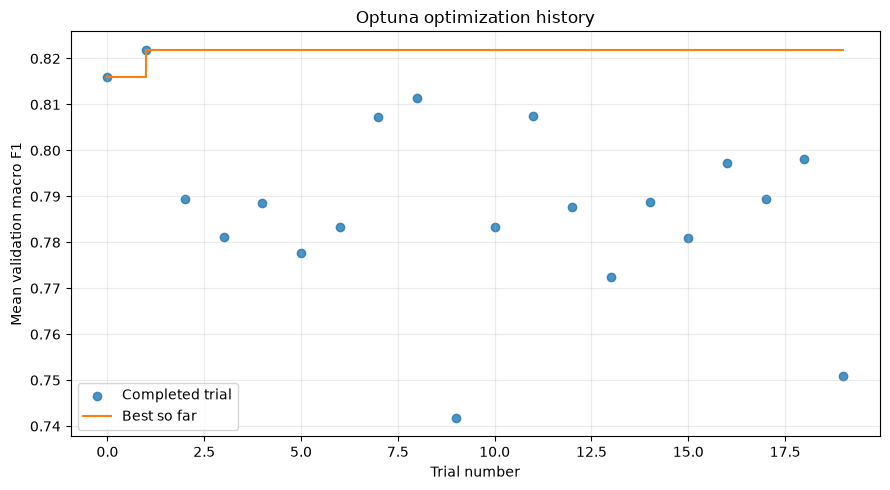

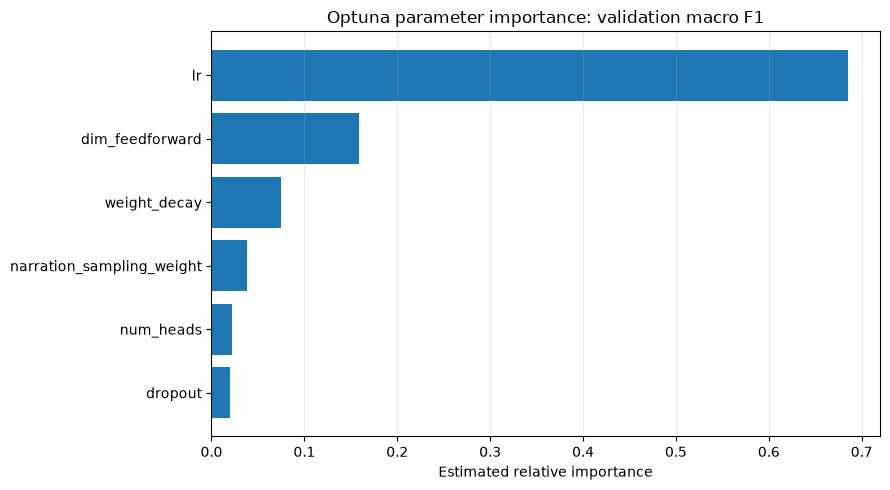

Graphs saved in: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\runs\optuna_joint\plots


In [5]:
# Cell purpose: Plot completed Optuna trials without starting or repeating training.
# Inputs: The in-memory study, or the saved SQLite study under runs/optuna_tuning.
# Outputs: Inline graphs and PNG files in the study's plots folder.

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import optuna
from config import CONFIG

# This cell can run by itself after a study has been saved.
plot_output = Path(globals().get('OUTPUT', CONFIG['run_dir'] / 'optuna_joint'))
plot_study_name = globals().get('STUDY_NAME', 'fixed_split_joint_refinement_v1')
plot_study = globals().get('study')
plot_database = plot_output / 'study.db'
if plot_study is None and plot_database.exists():
    plot_study = optuna.load_study(
        study_name=plot_study_name,
        storage='sqlite:///' + plot_database.resolve().as_posix(),
    )

completed = [] if plot_study is None else [
    trial for trial in plot_study.trials
    if trial.state == optuna.trial.TrialState.COMPLETE
    and trial.value is not None and np.isfinite(trial.value)
]
if not completed:
    print('No completed Optuna trials yet. Run the tuning cell, then rerun this plotting cell.')
else:
    plots = plot_output / 'plots'
    plots.mkdir(parents=True, exist_ok=True)
    trial_numbers = [trial.number for trial in completed]
    scores = np.array([trial.value for trial in completed])

    # Each dot is the mean validation macro F1 across the fixed search seeds.
    # The line shows the highest score found up to that trial.
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(trial_numbers, scores, label='Completed trial', alpha=0.8)
    ax.step(trial_numbers, np.maximum.accumulate(scores), where='post',
            color='tab:orange', label='Best so far')
    ax.set(xlabel='Trial number', ylabel='Mean validation macro F1',
           title='Optuna optimization history')
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(plots / 'optimization_history.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Importance estimates need multiple trials and changing parameter values.
    # They describe this search on this validation split, not causal effects.
    varying_parameters = [
        name for name in completed[0].params
        if all(name in trial.params for trial in completed)
        and len({trial.params[name] for trial in completed}) > 1
    ]
    if len(completed) >= 2 and varying_parameters:
        try:
            importance = optuna.importance.get_param_importances(
                plot_study,
                evaluator=optuna.importance.FanovaImportanceEvaluator(seed=42),
                params=varying_parameters,
            )
        except (ValueError, RuntimeError) as error:
            print('Parameter importance is not available for these trials:', error)
        else:
            names = list(reversed(importance))
            fig, ax = plt.subplots(figsize=(9, 5))
            ax.barh(names, [importance[name] for name in names])
            ax.set(xlabel='Estimated relative importance',
                   title='Optuna parameter importance: validation macro F1')
            ax.grid(axis='x', alpha=0.25)
            fig.tight_layout()
            fig.savefig(plots / 'parameter_importance.png', dpi=160, bbox_inches='tight')
            plt.show()
            plt.close(fig)
    else:
        print('Parameter importance needs at least two completed trials with changing parameters.')
    print('Graphs saved in:', plots)


## Export BestParamTuning
Run this cell after search or after the five-seed report. It can also run independently. It compares completed candidates from notebooks 08, 09 and 10 by their three-seed mean macro F1 (requiring the same split and seeds), then exports the winning candidate's highest-scoring available seed checkpoint. Run again after notebook 10 finishes to refresh the overall winner. No training runs here.


In [6]:
# Cell purpose: Export the overall best completed tuning candidate and study metadata.
# Inputs: Saved studies and completed seed checkpoints from notebooks 08 and 09.
# Outputs: BestParamTuning/best.pt, model.py, parameter/metadata JSON and study snapshots.
# No training is run. Rerunning refreshes the export using the available completed studies.
from config import CONFIG
from export_best_tuning import export_best_tuning

best_export = export_best_tuning(CONFIG['run_dir'].parent)


Exported: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\BestParamTuning
Winning study: fixed_split_architecture_v1 | trial: 6 | mean macro F1: 0.8219019308229694
Checkpoint seed: 99 | validation macro F1: 0.8501006036217305
